<a href="https://colab.research.google.com/github/ElvysSergioPascoal425/digital-onboarding-fraud-risk-analytics/blob/main/digital_onboarding_fraud_risk_analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Laboratório de prevenção a fraudes na abertura de contas digitais
Portfolio case study | Financial Services | Fraud Prevention | Risk Analytics | Python

Este notebook demonstra um fluxo analítico de avaliação de risco durante o onboarding digital, utilizando 30.000 registros sintéticos. O objetivo é ilustrar como sinais cadastrais, documentais, comportamentais, de dispositivo e de rede podem ser combinados para priorizar análises.
Aviso: projeto educacional com dados inteiramente artificiais. As regras, pesos, limiares e resultados são ilustrativos; não representam um motor de produção, não foram calibrados para uma instituição financeira e não devem ser usados para decisões reais sobre clientes.

Entregáveis
- Base sintética de propostas de onboarding.
- Análise exploratória e qualidade dos dados.
- Regras explicáveis e score heurístico.
- Modelo de classificação como benchmark analítico.
- Métricas, matriz de confusão e análise de variáveis.
- Recomendações de governança, monitoramento e melhoria contínua.


1. Escopo e hipótese de negócio
Célula 2 de 22

1. Escopo e hipótese de negócio
Problema: processos digitais precisam equilibrar prevenção a fraudes, experiência legítima do usuário e eficiência operacional.

Hipótese analítica: a combinação de sinais independentes — por exemplo, inconsistência documental, baixa confiança biométrica, velocidade de tentativas, reutilização de dispositivos e indicadores de rede — pode ajudar a priorizar propostas para revisão.

Decisões ilustradas
- Aprovação automatizada em cenários de baixo risco, sujeita a políticas e controles.
- Revisão adicional quando houver sinais intermediários ou inconclusivos.
- Bloqueio ou investigação somente após validações e políticas formais, nunca por um único indicador isolado.
Unidade de análise: uma proposta de abertura de conta digital.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, precision_recall_curve
)

SEED = 42
N_APPLICATIONS = 30_000
rng = np.random.default_rng(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print(f"Seed: {SEED} | Propostas sintéticas: {N_APPLICATIONS:,}")

Seed: 42 | Propostas sintéticas: 30,000


2. Geração da base sintética
Os atributos abaixo representam sinais que poderiam ser avaliados em um fluxo de onboarding. São variáveis artificiais e não correspondem a dados reais, documentos reais, IPs reais ou biometria real.

In [ ]:
n = N_APPLICATIONS

df = pd.DataFrame({
    "application_id": [f"APP-{i:06d}" for i in range(1, n + 1)],
    "applicant_age": rng.integers(18, 76, n),
    "email_age_days": np.clip(rng.gamma(2.2, 180, n).astype(int), 0, 2500),
    "phone_age_days": np.clip(rng.gamma(2.8, 220, n).astype(int), 0, 3000),
    "device_accounts_30d": np.clip(rng.poisson(0.7, n), 0, 12),
    "ip_accounts_24h": np.clip(rng.poisson(1.0, n), 0, 15),
    "geo_distance_km": np.round(np.clip(rng.gamma(1.2, 35, n), 0, 900), 1),
    "ocr_confidence": np.round(rng.beta(18, 2, n), 3),
    "selfie_match_score": np.round(rng.beta(17, 2.5, n), 3),
    "liveness_score": np.round(rng.beta(18, 2, n), 3),
    "name_document_match": rng.binomial(1, 0.965, n),
    "ip_vpn_proxy": rng.binomial(1, 0.055, n),
    "device_emulator": rng.binomial(1, 0.025, n),
    "device_rooted": rng.binomial(1, 0.035, n),
    "attempts_last_hour": np.clip(rng.poisson(0.8, n), 0, 20),
    "disposable_email": rng.binomial(1, 0.035, n),
    "address_phone_mismatch": rng.binomial(1, 0.075, n),
    "signup_night": rng.binomial(1, 0.22, n),
    "address_completeness": np.round(rng.beta(15, 2, n), 3)
})

# Sinal sintético de risco latente para gerar o rótulo educacional.
risk_logit = (
    -4.15
    + 0.55 * (df["device_accounts_30d"] >= 3)
    + 0.42 * (df["ip_accounts_24h"] >= 4)
    + 0.85 * (df["geo_distance_km"] >= 250)
    + 1.00 * (df["ocr_confidence"] < 0.72)
    + 1.15 * (df["selfie_match_score"] < 0.70)
    + 1.20 * (df["liveness_score"] < 0.72)
    + 0.90 * (df["name_document_match"] == 0)
    + 0.80 * df["ip_vpn_proxy"]
    + 1.00 * df["device_emulator"]
    + 0.55 * df["device_rooted"]
    + 0.11 * (df["attempts_last_hour"] >= 3)
    + 0.75 * df["disposable_email"]
    + 0.65 * df["address_phone_mismatch"]
    + 0.25 * df["signup_night"]
    + 0.45 * (df["email_age_days"] < 7)
    + 0.35 * (df["phone_age_days"] < 7)
)

fraud_probability = 1 / (1 + np.exp(-risk_logit))
df["is_fraud"] = rng.binomial(1, fraud_probability)

print("Dimensão:", df.shape)
print("Taxa sintética de fraude:", f"{df['is_fraud'].mean():.2%}")
display(df.head())

Dimensão: (30000, 20)
Taxa sintética de fraude: 2.54%


,application_id,applicant_age,email_age_days,phone_age_days,device_accounts_30d,ip_accounts_24h,geo_distance_km,ocr_confidence,selfie_match_score,liveness_score,name_document_match,ip_vpn_proxy,device_emulator,device_rooted,attempts_last_hour,disposable_email,address_phone_mismatch,signup_night,address_completeness,is_fraud
0,APP-000001,23,823,567,0,4,75.8,0.975,0.940,0.904,1,0,0,0,2,0,0,0,0.931,0
1,APP-000002,62,424,326,0,0,45.5,0.946,0.980,0.981,1,0,0,0,3,0,0,0,0.952,0
2,APP-000003,55,987,632,1,1,34.9,0.947,0.757,0.873,1,1,0,0,0,0,0,0,0.865,0
3,APP-000004,43,426,1226,0,0,45.9,0.832,0.913,0.767,0,0,0,0,0,0,0,1,0.909,0
4,APP-000005,43,240,110,0,1,61.9,0.956,0.859,0.948,1,0,0,0,0,0,0,1,0.910,0


3. Qualidade e entendimento dos dados
Antes de aplicar regras ou modelos, verificar granularidade, duplicidade, valores ausentes e distribuição do alvo. Em um ambiente real, também seria necessário validar linhagem, origem, consentimento/base legal, retenção, controles de acesso e qualidade dos fornecedores.

In [ ]:
quality = pd.DataFrame({
    "metric": ["rows", "columns", "duplicate_application_ids", "missing_cells", "synthetic_fraud_rate"],
    "value": [
        len(df),
        df.shape[1],
        df["application_id"].duplicated().sum(),
        int(df.isna().sum().sum()),
        df["is_fraud"].mean()
    ]
})
display(quality)

display(df.describe(include="all").T)

,metric,value
0,rows,30000.000000
1,columns,20.000000
2,duplicate_application_ids,0.000000
3,missing_cells,0.000000
4,synthetic_fraud_rate,0.025367


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
application_id,30000,30000,APP-000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
applicant_age,30000.0,NaN,NaN,NaN,46.429933,16.718802,18.0,32.0,46.0,61.0,75.0
email_age_days,30000.0,NaN,NaN,NaN,395.3778,267.93658,1.0,199.0,335.0,529.0,2500.0
phone_age_days,30000.0,NaN,NaN,NaN,614.894267,370.677239,5.0,342.0,543.0,808.0,3000.0
device_accounts_30d,30000.0,NaN,NaN,NaN,0.7011,0.839037,0.0,0.0,1.0,1.0,6.0
ip_accounts_24h,30000.0,NaN,NaN,NaN,1.004167,1.006272,0.0,0.0,1.0,2.0,7.0
geo_distance_km,30000.0,NaN,NaN,NaN,42.1451,38.4609,0.0,14.3,31.3,58.3,435.0
ocr_confidence,30000.0,NaN,NaN,NaN,0.900162,0.06544,0.51,0.865,0.913,0.949,1.0
selfie_match_score,30000.0,NaN,NaN,NaN,0.87137,0.073973,0.425,0.829,0.884,0.927,0.998
liveness_score,30000.0,NaN,NaN,NaN,0.89988,0.065678,0.435,0.865,0.913,0.949,0.999


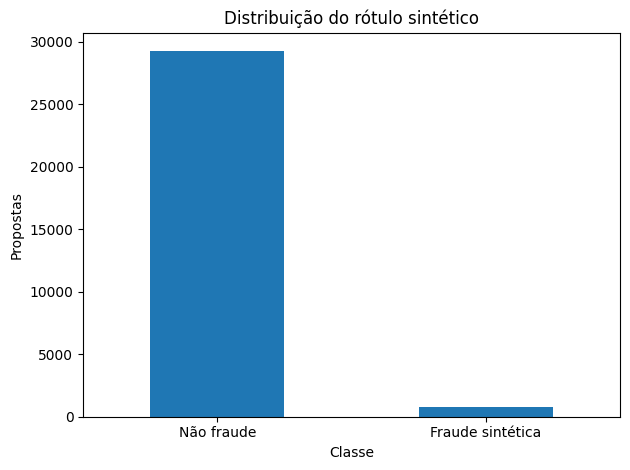

In [ ]:
class_counts = df["is_fraud"].value_counts().rename(index={0: "Não fraude", 1: "Fraude sintética"})
class_counts.plot(kind="bar", title="Distribuição do rótulo sintético", xlabel="Classe", ylabel="Propostas")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

4. Regras explicáveis de sinalização
As regras são intencionalmente transparentes. Cada sinal contribui com pontos para um score heurístico. Os pesos e cortes são exemplificativos, não thresholds recomendados para produção.

Evite tratar VPN, horário noturno, idade do e-mail ou distância geográfica como prova isolada de fraude. Esses sinais podem gerar falsos positivos e precisam de contexto, validação e monitoramento.

In [ ]:
rules = {
    "device_reuse": (df["device_accounts_30d"] >= 3, 15),
    "ip_velocity": (df["ip_accounts_24h"] >= 4, 12),
    "geo_anomaly": (df["geo_distance_km"] >= 250, 10),
    "low_ocr_confidence": (df["ocr_confidence"] < 0.72, 15),
    "low_selfie_match": (df["selfie_match_score"] < 0.70, 18),
    "low_liveness": (df["liveness_score"] < 0.72, 18),
    "name_document_mismatch": (df["name_document_match"] == 0, 20),
    "vpn_proxy": (df["ip_vpn_proxy"] == 1, 7),
    "emulator": (df["device_emulator"] == 1, 12),
    "rooted_device": (df["device_rooted"] == 1, 6),
    "high_attempt_velocity": (df["attempts_last_hour"] >= 3, 8),
    "disposable_email": (df["disposable_email"] == 1, 8),
    "address_phone_mismatch": (df["address_phone_mismatch"] == 1, 10),
    "very_new_email": (df["email_age_days"] < 7, 5),
    "very_new_phone": (df["phone_age_days"] < 7, 5)
}

for rule_name, (condition, points) in rules.items():
    df[f"rule_{rule_name}"] = condition.astype(int)

df["rule_hits"] = df[[f"rule_{name}" for name in rules]].sum(axis=1)
df["heuristic_risk_score"] = sum(
    condition.astype(int) * points for condition, points in rules.values()
)

def risk_band(score):
    if score >= 65:
        return "Crítico"
    if score >= 40:
        return "Alto"
    if score >= 20:
        return "Médio"
    return "Baixo"

df["risk_band"] = df["heuristic_risk_score"].apply(risk_band)

display(df[[
    "application_id", "heuristic_risk_score", "risk_band", "rule_hits", "is_fraud"
]].head(12))

,application_id,heuristic_risk_score,risk_band,rule_hits,is_fraud
0,APP-000001,12,Baixo,1,0
1,APP-000002,8,Baixo,1,0
2,APP-000003,7,Baixo,1,0
3,APP-000004,20,Médio,1,0
4,APP-000005,0,Baixo,0,0
5,APP-000006,0,Baixo,0,0
6,APP-000007,18,Baixo,1,0
7,APP-000008,0,Baixo,0,0
8,APP-000009,15,Baixo,1,0
9,APP-000010,12,Baixo,1,0


5. Priorização operacional
A classificação abaixo representa uma sugestão de fila analítica. Uma política real precisa definir critérios de elegibilidade, etapas de revisão, evidências mínimas, tratamento de exceções, contestação e trilha de auditoria.

,applications,fraud_rate,avg_score,avg_rule_hits
risk_band,,,,
Baixo,28016.000000,2.30%,3.4,0.33
Médio,1910.000000,5.50%,24.4,1.72
Alto,74.000000,14.86%,44.5,3.23
Crítico,nan,nan%,nan,nan


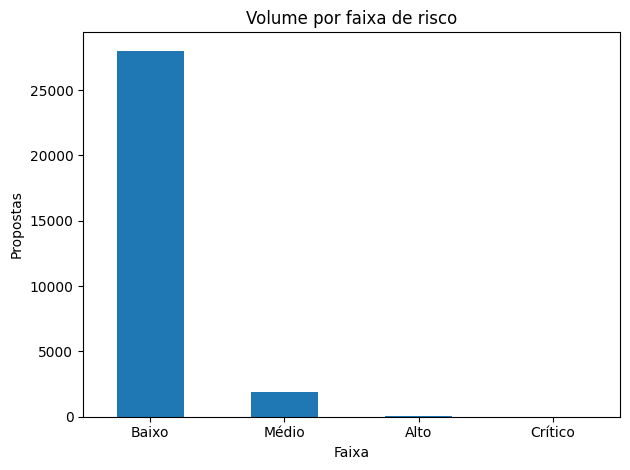

In [ ]:
band_summary = (
    df.groupby("risk_band", observed=False)
      .agg(
          applications=("application_id", "count"),
          fraud_rate=("is_fraud", "mean"),
          avg_score=("heuristic_risk_score", "mean"),
          avg_rule_hits=("rule_hits", "mean")
      )
      .reindex(["Baixo", "Médio", "Alto", "Crítico"])
)
display(band_summary.style.format({
    "fraud_rate": "{:.2%}",
    "avg_score": "{:.1f}",
    "avg_rule_hits": "{:.2f}"
}))

band_summary["applications"].plot(kind="bar", title="Volume por faixa de risco", ylabel="Propostas", xlabel="Faixa")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

6. Benchmark de Machine Learning
Um Random Forest será usado como benchmark didático. O alvo é o rótulo sintético gerado na seção 2. O modelo não deve ser interpretado como pronto para produção.

Cuidados metodológicos para um caso real:
- Separação temporal entre treino e teste, quando aplicável.
- Prevenção de vazamento de informação (data leakage).
- Avaliação por coortes, canais, segmentos e fornecedores.
- Monitoramento de drift, estabilidade e desempenho.
- Revisão de vieses, explicabilidade, privacidade e impacto sobre clientes.

In [ ]:
feature_cols = [
    "applicant_age", "email_age_days", "phone_age_days",
    "device_accounts_30d", "ip_accounts_24h", "geo_distance_km",
    "ocr_confidence", "selfie_match_score", "liveness_score",
    "name_document_match", "ip_vpn_proxy", "device_emulator",
    "device_rooted", "attempts_last_hour", "disposable_email",
    "address_phone_mismatch", "signup_night", "address_completeness"
]

X = df[feature_cols]
y = df["is_fraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

model = RandomForestClassifier(
    n_estimators=250,
    max_depth=10,
    min_samples_leaf=8,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)
model.fit(X_train, y_train)

pred_proba = model.predict_proba(X_test)[:, 1]
pred_label = (pred_proba >= 0.50).astype(int)

print("ROC-AUC:", round(roc_auc_score(y_test, pred_proba), 4))
print("Average Precision:", round(average_precision_score(y_test, pred_proba), 4))
print()
print(classification_report(y_test, pred_label, target_names=["Não fraude", "Fraude"], zero_division=0))

ROC-AUC: 0.521
Average Precision: 0.029

              precision    recall  f1-score   support

  Não fraude       0.97      0.98      0.98      7310
      Fraude       0.04      0.03      0.03       190

    accuracy                           0.96      7500
   macro avg       0.51      0.51      0.51      7500
weighted avg       0.95      0.96      0.96      7500



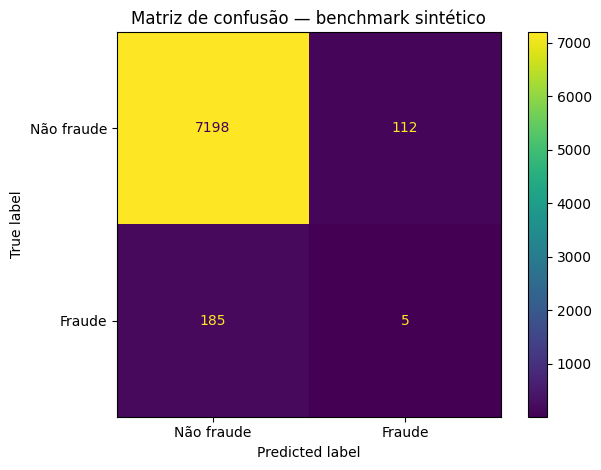

In [ ]:
cm = confusion_matrix(y_test, pred_label)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Não fraude", "Fraude"])
disp.plot(values_format="d")
plt.title("Matriz de confusão — benchmark sintético")
plt.tight_layout()
plt.show()

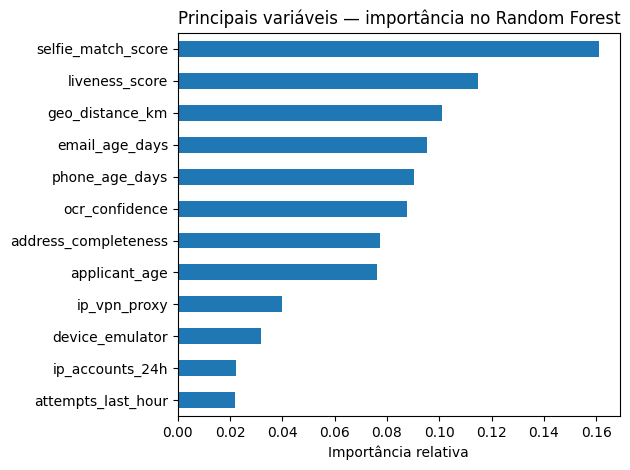

,feature_importance
selfie_match_score,0.161086
liveness_score,0.114927
geo_distance_km,0.101237
email_age_days,0.095193
phone_age_days,0.090368
ocr_confidence,0.087597
address_completeness,0.077246
applicant_age,0.076373
ip_vpn_proxy,0.039952
device_emulator,0.031893


In [ ]:
importance = (
    pd.Series(model.feature_importances_, index=feature_cols)
      .sort_values(ascending=False)
      .head(12)
)
importance.sort_values().plot(kind="barh", title="Principais variáveis — importância no Random Forest")
plt.xlabel("Importância relativa")
plt.tight_layout()
plt.show()

display(importance.to_frame("feature_importance"))

7. Análise de limiar e trade-off
O limiar de 0,50 é apenas um ponto inicial para demonstração. Em prevenção a fraudes, a escolha do threshold deve considerar custo de fraude, capacidade de revisão, taxa de falso positivo, impacto na conversão e apetite a risco. Não existe um corte universal.

,threshold,precision,recall
0,0.141693,0.025333,1.000000
750,0.272961,0.025037,0.889474
1500,0.302202,0.025000,0.789474
2250,0.323441,0.025905,0.715789
3000,0.341046,0.026000,0.615789
3750,0.356799,0.025600,0.505263
4500,0.372350,0.027000,0.426316
5250,0.388685,0.029778,0.352632
6000,0.406401,0.033333,0.263158
6750,0.431471,0.032000,0.126316


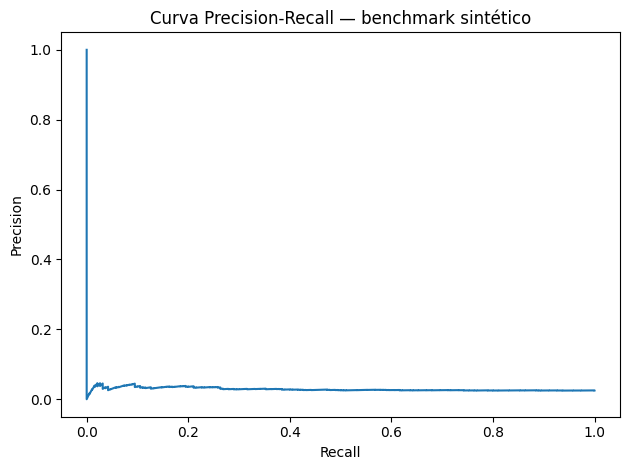

In [ ]:
precision, recall, thresholds = precision_recall_curve(y_test, pred_proba)
pr_curve = pd.DataFrame({
    "threshold": np.r_[thresholds, np.nan],
    "precision": precision,
    "recall": recall
})
display(pr_curve.iloc[::max(1, len(pr_curve)//10)].head(12))

plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curva Precision-Recall — benchmark sintético")
plt.tight_layout()
plt.show()

| Indicador | Definição ilustrativa | Uso |
|---|---|---|
| Fraud rate por coorte | Fraudes confirmadas / propostas da coorte | Acompanhar risco |
| Approval rate | Propostas aprovadas / propostas recebidas | Monitorar conversão |
| Manual review rate | Propostas enviadas à revisão / total | Dimensionar operação |
| False positive rate | Legítimas sinalizadas como fraude / legítimas | Controlar atrito |
| Precision da fila | Fraudes confirmadas / alertas revisados | Eficiência da triagem |
| Tempo de decisão | Tempo entre início e decisão | Eficiência operacional |
| Reincidência de dispositivo | Dispositivos associados a múltiplas ocorrências | Identificar padrões |
| Drift de variáveis | Mudança de distribuição dos sinais | Monitorar estabilidade |

Os indicadores dependem de rótulos confiáveis e maduros. Fraudes confirmadas podem chegar com atraso; portanto, é importante explicitar janelas de maturação e data de referência.

In [ ]:
executive_kpis = pd.DataFrame({
    "KPI": [
        "Total de propostas",
        "Fraudes sintéticas",
        "Taxa sintética de fraude",
        "Propostas em risco alto/crítico",
        "Participação alto/crítico"
    ],
    "Value": [
        len(df),
        int(df["is_fraud"].sum()),
        f"{df['is_fraud'].mean():.2%}",
        int(df["risk_band"].isin(["Alto", "Crítico"]).sum()),
        f"{df['risk_band'].isin(['Alto', 'Crítico']).mean():.2%}"
    ]
})
display(executive_kpis)

,KPI,Value
0,Total de propostas,30000
1,Fraudes sintéticas,761
2,Taxa sintética de fraude,2.54%
3,Propostas em risco alto/crítico,74
4,Participação alto/crítico,0.25%


9. Governança e controles recomendados
1. Finalidade e minimização: coletar apenas atributos necessários e compatíveis com a finalidade informada.
2. Privacidade e segurança: controlar acesso, retenção, compartilhamento e rastreabilidade dos dados.
3. Qualidade de fornecedores: acompanhar cobertura, disponibilidade, precisão e mudanças de versão de sinais externos.
4. Human-in-the-loop: definir revisão humana para casos ambíguos e mecanismos de contestação.
5. Explicabilidade: registrar sinais acionados, versão das regras/modelo e justificativa da decisão.
6. Monitoramento: acompanhar performance, drift, falsos positivos, conversão e disparidades entre grupos relevantes.
7. Gestão de mudanças: versionar regras, pesos, thresholds e modelos; testar antes de publicar.
8. Resiliência operacional: prever indisponibilidade de biometria, OCR, device intelligence e serviços de consulta.
9. Auditoria: manter trilha de decisão, evidências e aprovações conforme políticas internas e requisitos aplicáveis.
Este notebook não constitui parecer jurídico ou regulatório. A implementação real deve passar pelas áreas responsáveis por risco, compliance, privacidade, segurança, jurídico e auditoria.

10. Conclusões
Este estudo demonstra como sinais de identidade, dispositivo, rede e comportamento podem ser organizados em uma estrutura analítica para priorização de onboarding.

Principais aprendizados
- Regras explicáveis facilitam a comunicação com operação e governança.
- Modelos podem complementar regras, mas precisam de validação e monitoramento.
- Métricas de risco devem ser analisadas junto com conversão e falsos positivos.
- Um score não substitui política, investigação, evidência ou julgamento especializado.
Próximos passos de evolução
- Criar validação temporal e backtesting.
- Comparar regras, Logistic Regression e modelos baseados em árvores.
- Construir dashboard executivo por canal, etapa e motivo de alerta.
- Implementar explicabilidade por proposta e monitoramento de drift.

Author: Elvys Pascoal
Portfolio: Fraud Prevention | Digital Risk | Data Analytics | AI & Process Automation
Data: Synthetic / Educational Use Only